Part B - Independent Tasks

B1. Misssing Value Audit

Load air_quality.csv
1) Print the shpae and first 6 rows of the dataset

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("air_quality.csv")

In [7]:
print("Shape of the dataset : ", df.shape)

Shape of the dataset :  (200, 6)


In [8]:
print("First 6 rows of dataset")
print(df.head(6))

First 6 rows of dataset
   temperature  humidity  rainfall    aqi  wind_speed  vehicle_count
0         27.9      48.2      1.71   40.0        1.55          464.0
1         24.7      61.0       NaN   81.2       14.61          614.0
2         16.0      60.5      8.24  221.6        1.20          131.0
3         27.0      56.7      1.62  149.3       16.14          803.0
4         25.8      64.6      4.24  196.7         NaN          190.0
5         36.7      51.8     10.04    NaN       22.69         1391.0


2. Print missing count and missing percentage per column. Identify the column with the highest missing rate and state whether any column exceeds 15%.

In [9]:
missing_cnt = df.isnull().sum()
print("Missing count : ")
print(missing_cnt)
print()
missing_pct = (df.isnull().mean()*100).round(1)
print("Missing percentage per column : ")
print(missing_pct)
print()
print("Highest missing rate column name is : rainfall")
print("No column exceeds 15%")

Missing count : 
temperature      18
humidity         22
rainfall         30
aqi              14
wind_speed       25
vehicle_count    10
dtype: int64

Missing percentage per column : 
temperature       9.0
humidity         11.0
rainfall         15.0
aqi               7.0
wind_speed       12.5
vehicle_count     5.0
dtype: float64

Highest missing rate column name is : rainfall
No column exceeds 15%


3)	Draw a missing-value heatmap with a descriptive title. In a markdown cell write one sentence on what the pattern suggests about sensor behaviour.

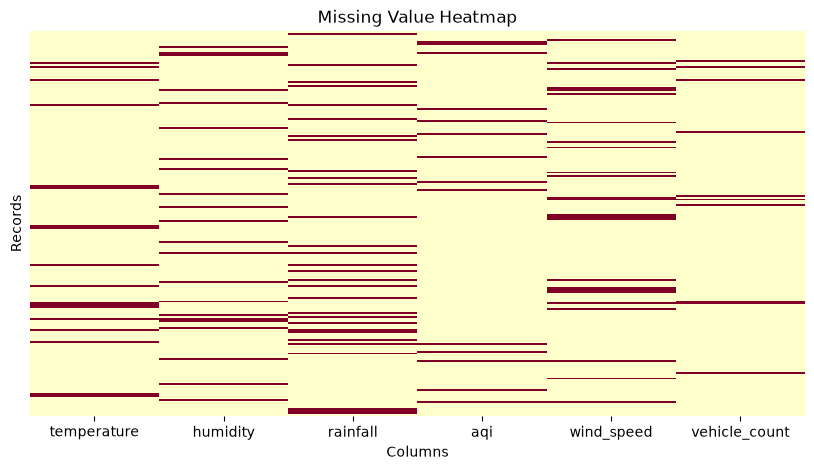

In [19]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False, cmap="YlOrRd", yticklabels=False)
plt.title("Missing Value Heatmap")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.show()

4.	Run describe() and note for each column whether mean is above or below the median. Capture this in a markdown cell — you will use it to justify imputation choices below.

In [11]:
print(df.describe())

       temperature    humidity    rainfall         aqi  wind_speed  \
count   182.000000  178.000000  170.000000  186.000000  175.000000   
mean     27.769780   64.840449    6.123471  115.859677   11.303429   
std       4.574481   11.279858    4.340003   64.368975   22.214313   
min      15.300000   38.000000    0.490000   19.200000    1.020000   
25%      24.625000   57.825000    2.870000   71.825000    1.955000   
50%      27.900000   64.350000    4.870000  104.000000    3.870000   
75%      30.600000   72.675000    9.455000  155.675000   10.190000   
max      39.900000   95.400000   22.040000  480.900000  207.600000   

       vehicle_count  
count     190.000000  
mean     2830.831579  
std     19617.514249  
min       100.000000  
25%       251.750000  
50%       497.000000  
75%      1129.000000  
max    267588.000000  


In [12]:
for col in df.columns:
    mean = df[col].mean()
    median = df[col].median()

    if mean < median : 
        print(col ,": mean < median")
    else :
        print(col ,": median < mean")

temperature : mean < median
humidity : median < mean
rainfall : median < mean
aqi : median < mean
wind_speed : median < mean
vehicle_count : median < mean


B2. Imputation

5. In a markdown cell, state which statistic (mean or median) you chose for each column and why, referencing the distribtuition family and your describe() findings.

For mean I will chose temperature and humidity column and for median I will choose other columns.

6.	Apply imputation to all six columns and confirm zero missing values remain.

In [13]:
df_clean = df.copy()

df_clean["temperature"] = df_clean["temperature"].fillna(df_clean["temperature"].mean())
df_clean["humidity"] = df_clean["humidity"].fillna(df_clean["humidity"].mean())
df_clean["rainfall"] = df_clean["rainfall"].fillna(df_clean["rainfall"].mean())
df_clean["aqi"] = df_clean["aqi"].fillna(df_clean["aqi"].mean())
df_clean["wind_speed"] = df_clean["wind_speed"].fillna(df_clean["wind_speed"].mean())
df_clean["vehicle_count"] = df_clean["vehicle_count"].fillna(df_clean["vehicle_count"].mean())

print(df_clean.isnull().sum())

temperature      0
humidity         0
rainfall         0
aqi              0
wind_speed       0
vehicle_count    0
dtype: int64


7. For rainfall, plot before-and-after KDE curves on the same axes. Write one sentence: did imputation shift the centre, and is that expected given your choice of statistic?

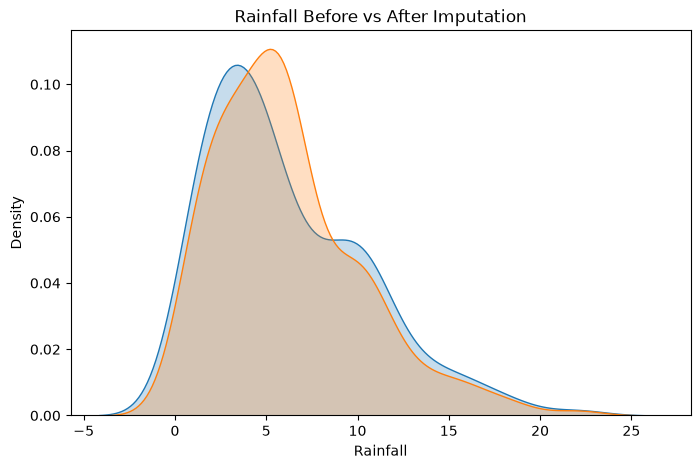

In [20]:
plt.figure(figsize=(8,5))

sns.kdeplot(df["rainfall"], label="Before", fill=True)
sns.kdeplot(df_clean["rainfall"], label="After", fill=True)

plt.title("Rainfall Before vs After Imputation")
plt.xlabel("Rainfall")
plt.ylabel("Density")


plt.show()

B3. Histograms

8. Draw histograms of all six columns in a 2x3 grid. Write one sentence per column describing its shape and matching it to the expected distribtuion family.

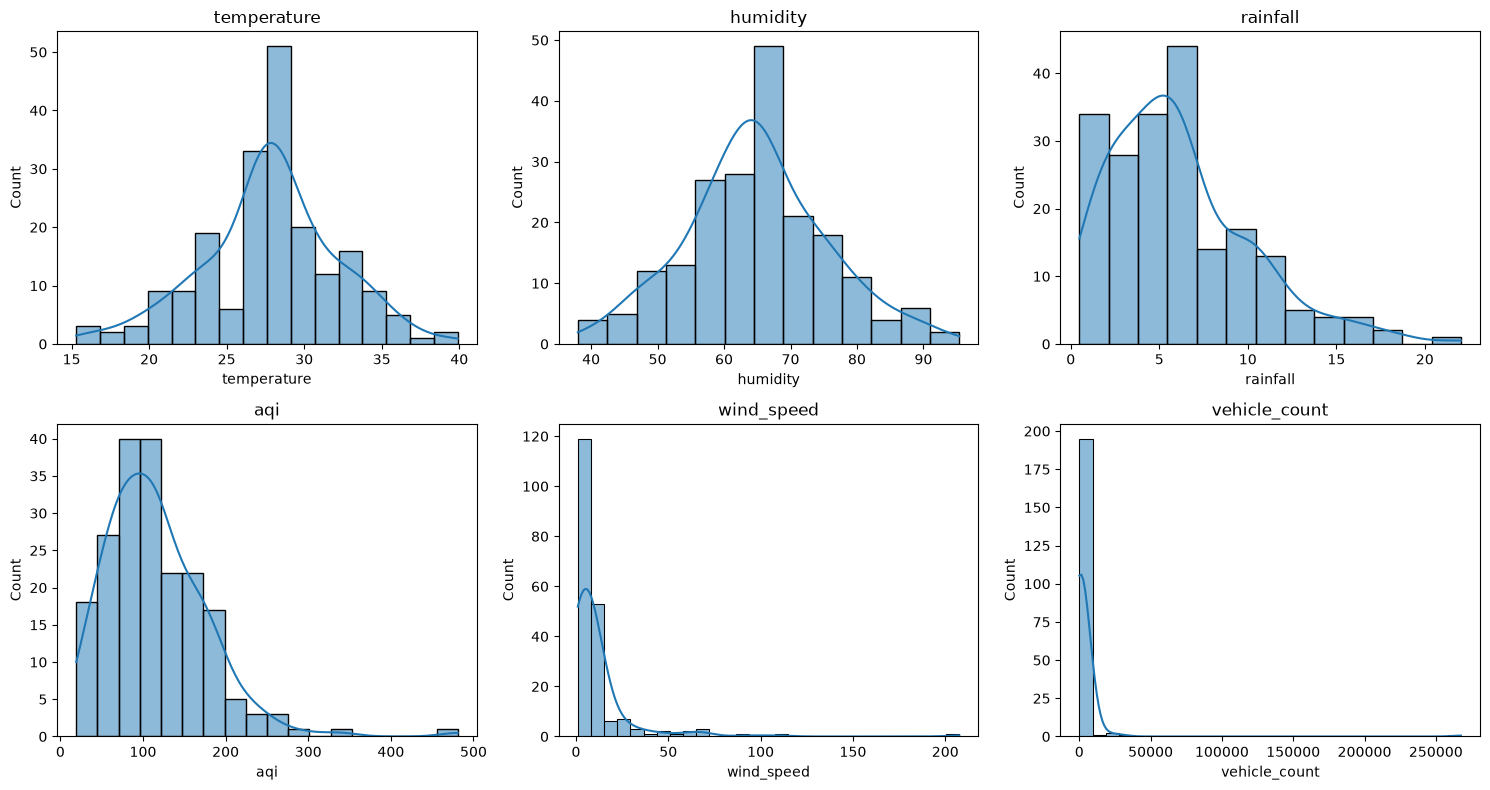

In [15]:
fig, axes = plt.subplots(2,3, figsize=(15,8))

cols = df_clean.columns

for ax,col in zip(axes.flatten(), cols):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

9. Draw a single histogram for aqi with a KDE overlay and vertical lines for mean and median. From this plot, state whether aqi is right-skewed or left-skewed and justify using the positions of the two lines.

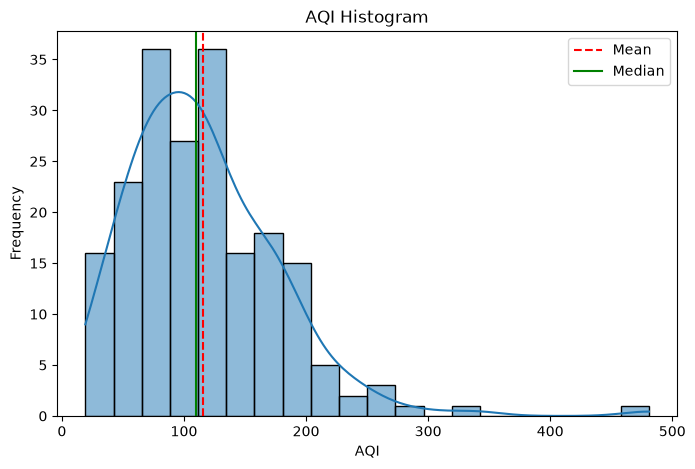

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(df_clean["aqi"], bins=20, kde=True)

plt.axvline(df_clean["aqi"].mean(),
            color='red',
            linestyle='--',
            label="Mean")

plt.axvline(df_clean["aqi"].median(),
            color='green',
            label="Median")

plt.title("AQI Histogram")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.legend()

plt.show()

10. Draw vehicle_count twice side by side — normal y-axis and log-scale y-axis. Explain what the log-scale appearance reveals about this column's distribution.

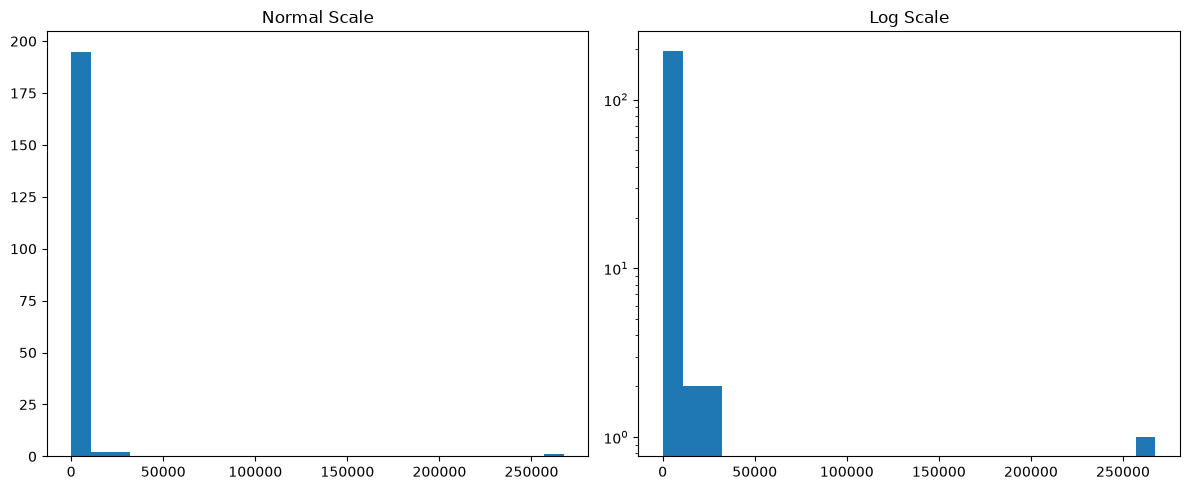

In [17]:
fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].hist(df_clean["vehicle_count"], bins=25)
ax[0].set_title("Normal Scale")

ax[1].hist(df_clean["vehicle_count"], bins=25)
ax[1].set_yscale("log")
ax[1].set_title("Log Scale")

plt.tight_layout()
plt.show()

11.	Draw z-scored box plots of temperature, humidity, and rainfall on one figure. State which column has the most outlier points and whether that matches its distribution family.

In [18]:
from scipy.stats import zscore

cols = ["temperature","humidity","rainfall"]

normed = df_clean[cols].apply(zscore)
normed.boxplot()


plt.title("Z-score Boxplots")
plt.ylabel("Z-score")
plt.show()

ModuleNotFoundError: No module named 'scipy'

12.	Apply the IQR rule to wind_speed: print the number of outliers and show those rows. Write one sentence interpreting what an extreme wind_speed city-day might represent.

In [ ]:
Q1 = df_clean["wind_speed"].quantile(0.25)
Q3 = df_clean["wind_speed"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

outliers = df_clean[(df_clean["wind_speed"]<lower) |
                    (df_clean["wind_speed"]>upper)]

print("Number of Outliers:", len(outliers))

print(outliers)

Number of Outliers: 18
     temperature   humidity   rainfall         aqi  wind_speed  vehicle_count
26      22.70000  53.300000   6.123471   57.900000       92.69     801.000000
45      29.00000  48.100000   6.123471   98.600000       64.23     148.000000
53      20.60000  56.900000   0.660000  115.859677       25.13     977.000000
72      20.30000  55.900000   6.123471  128.500000      207.60    4036.000000
81      27.76978  71.400000   1.180000  184.400000       29.09     205.000000
90      26.60000  61.400000  10.610000  146.200000       30.28    2830.831579
91      20.80000  64.840449   6.350000  108.900000       69.98     205.000000
98      28.90000  64.840449   9.690000  127.700000       68.94     859.000000
107     24.60000  59.800000  12.240000  480.900000       39.21     497.000000
109     29.00000  64.840449   2.050000  236.000000       65.52    1632.000000
115     28.70000  64.840449   6.123471   65.600000       59.89     396.000000
118     39.10000  62.400000   3.910000  1

13. Draw violin plots of temperature, humidity, rainfall, and aqi side by side. Contrast the shape of the Normal violins with the Gamma violins in a markdown cell.

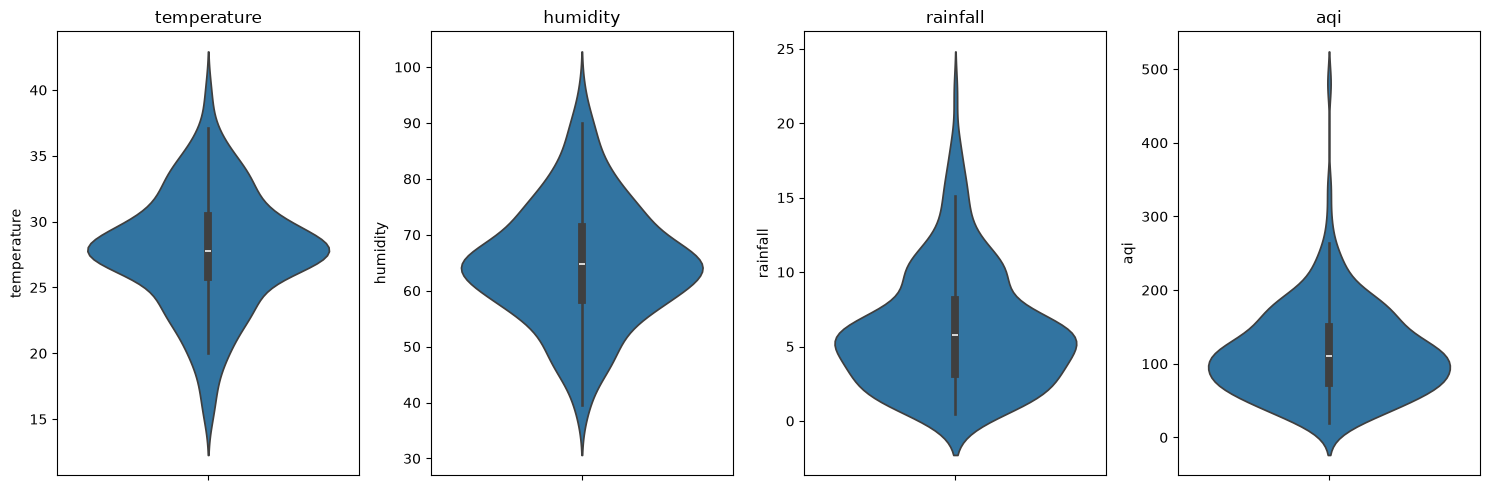

In [ ]:
fig, ax = plt.subplots(1,4, figsize=(15,5))

cols = ["temperature","humidity","rainfall","aqi"]

for a,col in zip(ax,cols):
    sns.violinplot(y=df_clean[col], ax=a)
    a.set_title(col)

plt.tight_layout()
plt.show()

B5. Scatter, Pair Plot, and Correlation

14.	Draw three scatter plots: (a) humidity vs aqi, (b) wind_speed vs aqi, (c) temperature vs rainfall. Write one sentence per plot on whether and in which direction a trend is visible.

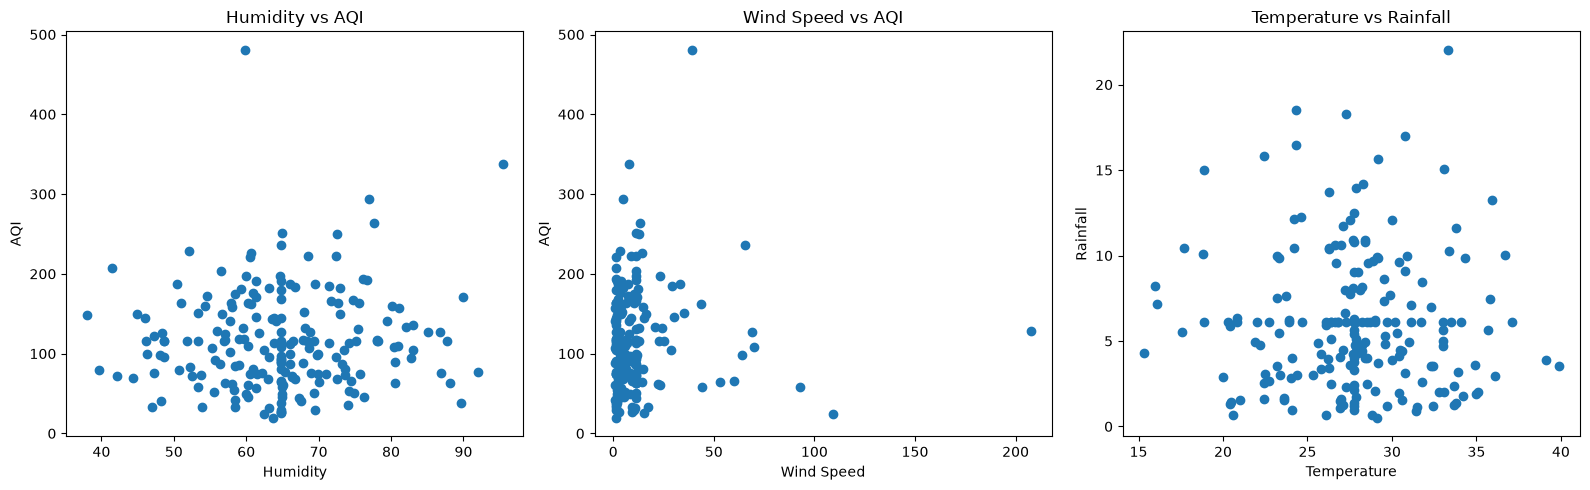

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(16,5))

ax[0].scatter(df_clean["humidity"], df_clean["aqi"])
ax[0].set_title("Humidity vs AQI")
ax[0].set_xlabel("Humidity")
ax[0].set_ylabel("AQI")

ax[1].scatter(df_clean["wind_speed"], df_clean["aqi"])
ax[1].set_title("Wind Speed vs AQI")
ax[1].set_xlabel("Wind Speed")
ax[1].set_ylabel("AQI")

ax[2].scatter(df_clean["temperature"], df_clean["rainfall"])
ax[2].set_title("Temperature vs Rainfall")
ax[2].set_xlabel("Temperature")
ax[2].set_ylabel("Rainfall")

plt.tight_layout()
plt.show()

15.	Redraw wind_speed vs aqi coloured by temperature (coolwarm, with colour bar). Describe whether high-temperature days cluster at high or low AQI and give a physical reason

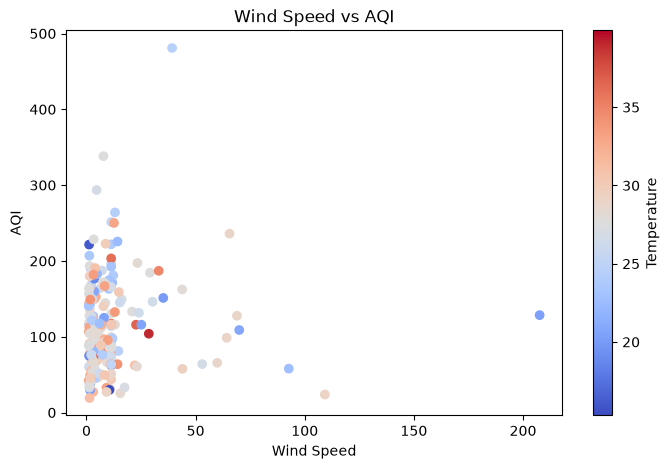

In [ ]:
plt.figure(figsize=(8,5))

sc = plt.scatter(df_clean["wind_speed"],
                 df_clean["aqi"],
                 c=df_clean["temperature"],
                 cmap="coolwarm")

plt.colorbar(sc, label="Temperature")

plt.title("Wind Speed vs AQI")
plt.xlabel("Wind Speed")
plt.ylabel("AQI")

plt.show()

16. Draw the correlation heatmap. State the pair with the highest absolute correlation and explain whether it matches what you saw in the scatter plots.

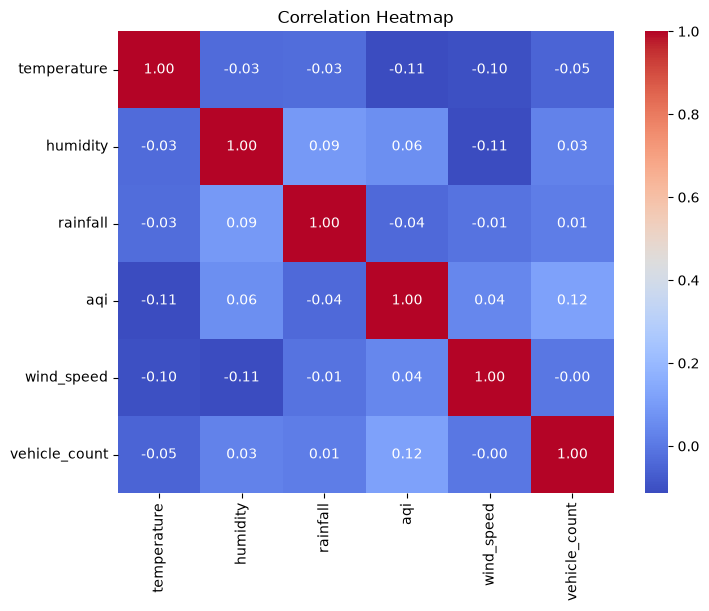

In [ ]:
corr = df_clean.corr()

plt.figure(figsize=(8,6))

sns.heatmap(corr,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

17.	Create df_dropped (drop all rows with any missing value) and df_imputed (df_clean). Compare shapes and draw side-by-side rainfall histograms. How much data is lost by dropping? Does the shape change?

Original Shape: (200, 6)
Dropped Shape: (101, 6)
Imputed Shape: (200, 6)


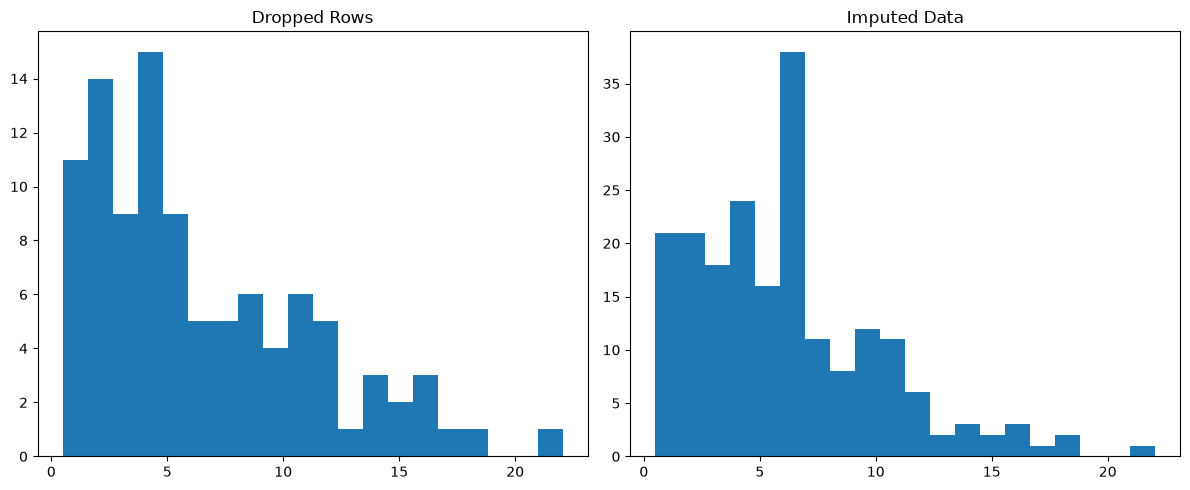

In [ ]:
df_dropped = df.dropna()

print("Original Shape:", df.shape)
print("Dropped Shape:", df_dropped.shape)
print("Imputed Shape:", df_clean.shape)

fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].hist(df_dropped["rainfall"], bins=20)
ax[0].set_title("Dropped Rows")

ax[1].hist(df_clean["rainfall"], bins=20)
ax[1].set_title("Imputed Data")

plt.tight_layout()
plt.show()

18.	Design one additional visualisation of your own choice not already used in B.1–B.5. Write two sentences: what does it show, and why did you choose this chart type?

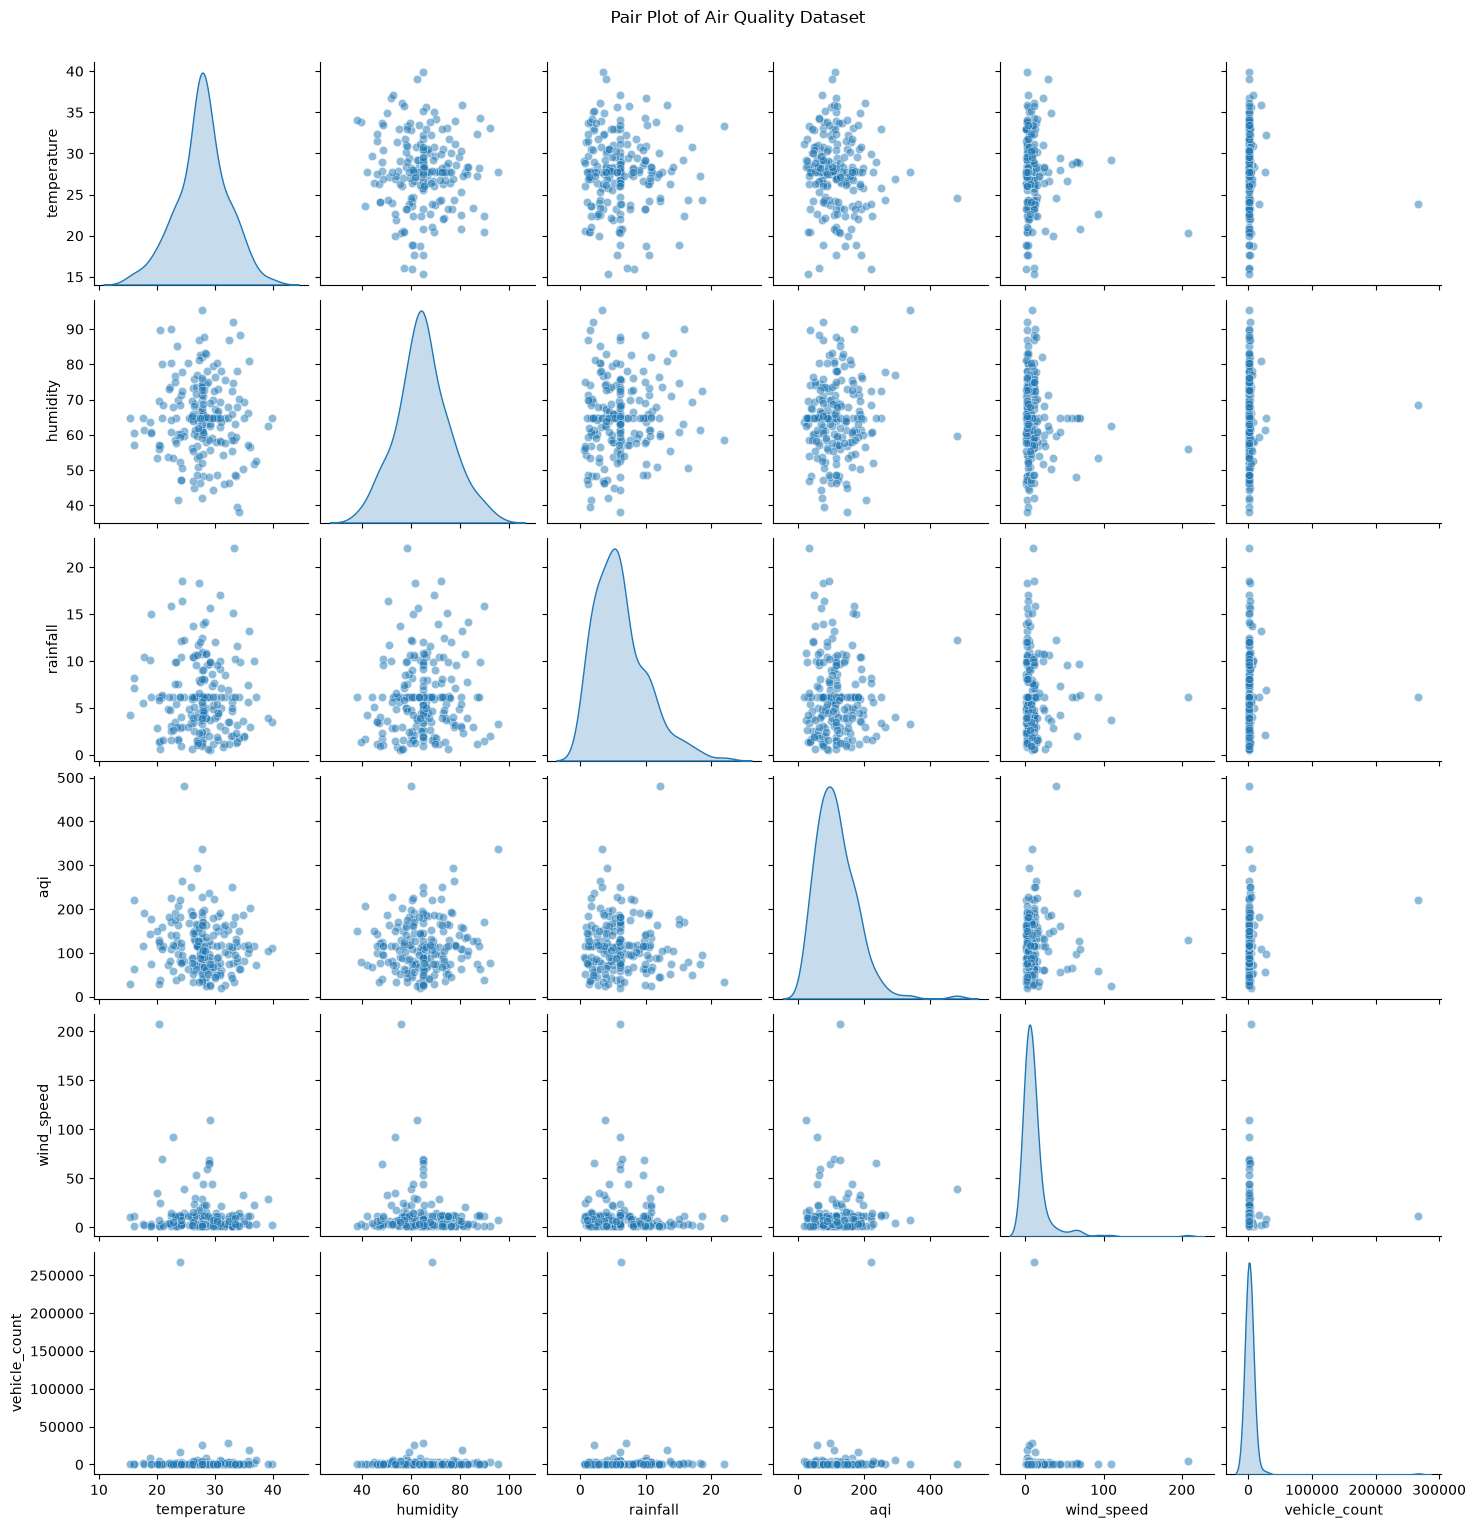

In [ ]:
sns.pairplot(df_clean,
             diag_kind="kde",
             plot_kws={"alpha":0.5})

plt.suptitle("Pair Plot of Air Quality Dataset", y=1.02)

plt.show()